KNN Accuracy: 0.5765765765765766
Naive Bayes Accuracy: 0.8918918918918919


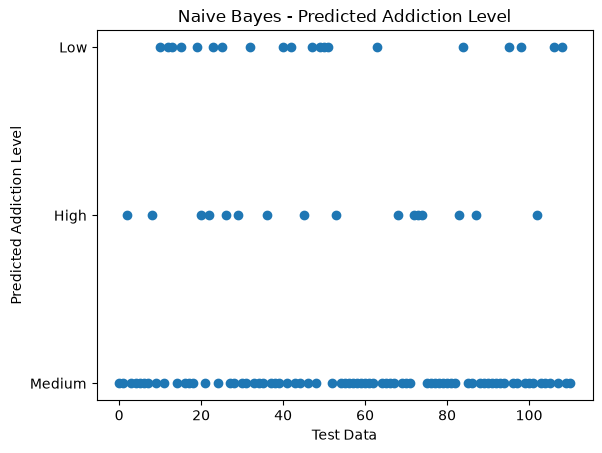

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Load own Smartphone Usage dataset
data = pd.read_csv("smartphone_usage.csv")

# Create Addiction Level
def get_addiction_level(row):

    score = (
        row["Screen_Time_Hours"] +
        row["Daily_Unlocks"] / 20 +
        row["Social_Media_Minutes"] / 60
    )

    if score < 10:
        return "Low"
    elif score < 18:
        return "Medium"
    else:
        return "High"


data["Addiction_Level"] = data.apply(
    get_addiction_level,
    axis=1
)

# Input and output
X = data.drop("Addiction_Level", axis=1)
y = data["Addiction_Level"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=32
)

# -------- KNN --------
knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))


# -------- Naive Bayes --------
nb = GaussianNB()

nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred))


# -------- Visualization --------
plt.scatter(
    range(len(y_test)),
    nb_pred
)

plt.xlabel("Test Data")
plt.ylabel("Predicted Addiction Level")
plt.title("Naive Bayes - Predicted Addiction Level")

plt.show()